# Step 0.5: Indicate data paths, save path

In [30]:
file_path1 = "D:\\AmygdalaMice\\M471\\Delay1\\monitor_Part1\\ampdata2026-03-10T11_15_11.bin" #data path for monitoring, part 1
file_path2 = "D:\\AmygdalaMice\\M471\\Delay1\\monitor_Part2\\ampdata2026-03-10T16_44_29.bin" #data path for monitoring, part 2
comb_path = "D:\\AmygdalaMice\\M471\\Delay1\\Combined_monitoring" #path for saving the combined bin file
comb_name = "D:\\AmygdalaMice\\M471\\Delay1\\Combined_monitoring\\combined_recording.bin" #path for saving the combined bin file
save_path = "D:\\AmygdalaMice\\M471\\Delay1\\Combined_monitoring\\SpikeSort\\Pipeline" #main folder for saving the output

import os
os.mkdir(comb_path)

# Step 1: load in data

(<matplotlib.collections.PolyCollection at 0x1c6897de1a0>,
 <matplotlib.collections.PolyCollection at 0x1c6897dc2b0>)

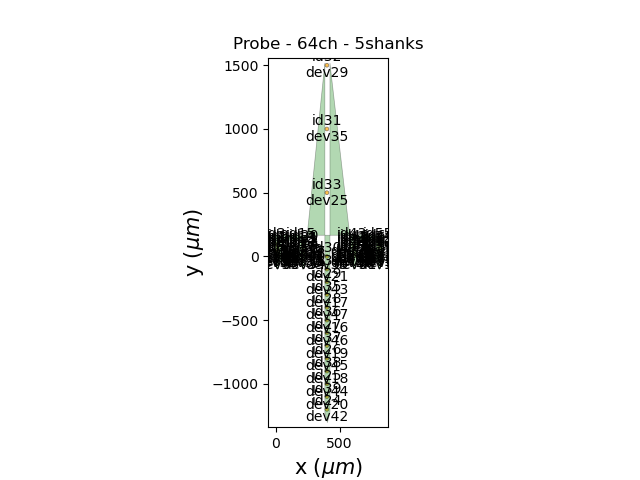

In [31]:
%matplotlib widget

import matplotlib.pyplot as plt
from probeinterface import Probe,combine_probes,write_csv
from probeinterface.plotting import plot_probe,plot_probegroup

import pandas as pd

import numpy as np

import spikeinterface.core as si
import spikeinterface.extractors as se
import spikeinterface.preprocessing as sp
import spikeinterface.postprocessing as spost
import spikeinterface.qualitymetrics as sqm

import spikeinterface.widgets as sw

import spikeinterface.sorters as ss

# Create a probe
probe_sites = pd.read_csv(r"D:\SpikeSorting\NRX_Buzsaki64_buz_lin_5X12_JDY_probeinterface.csv", header=0)

probe_5x12 = Probe(ndim=2,si_units='um',manufacturer='NeuroNexus',model_name='A5x12-16-Buz-Lin-5mm-100-200-160-177')

probe1 = Probe(ndim=2,si_units='um',manufacturer='NeuroNexus',model_name='A5x12-16-Buz-Lin-5mm-100-200-160-177')
probe1.set_contacts(positions=probe_sites[['X','Y']].to_numpy()[(probe_sites['K']==1)], shapes='square', shape_params={'width': 10})

probe2 = probe1.copy()
probe2.move([200,0])

probe3 = Probe(ndim=2,si_units='um',manufacturer='NeuroNexus',model_name='A5x12-16-Buz-Lin-5mm-100-200-160-177')
probe3.set_contacts(positions=probe_sites[['X','Y']].to_numpy()[(probe_sites['K']==3) | (probe_sites['K']==6)], shapes='circle', shape_params={'radius': 15})
probe3.create_auto_shape('tip')

probe4 = probe1.copy()
probe4.move([600,0])

probe5 = probe1.copy()
probe5.move([800,0])

probe1.create_auto_shape('tip')
probe2.create_auto_shape('tip')
probe4.create_auto_shape('tip')
probe5.create_auto_shape('tip')

probe_5x12 = combine_probes([probe1,probe2,probe3,probe4,probe5])
probe_5x12.set_contact_ids(probe_sites['PhysicalChannel'].to_numpy(int)-1)
probe_5x12.set_device_channel_indices(probe_sites['OEChannel'].to_numpy()-1)

plot_probe(probe_5x12, with_contact_id=True, with_device_index=True)

In [32]:
recording1 = si.read_binary(file_paths=file_path1,
                           sampling_frequency=30000,num_channels=64,dtype='uint16',gain_to_uV=0.195,offset_to_uV=-0.195*32767)

recording2 = si.read_binary(file_paths=file_path2,
                           sampling_frequency=30000,num_channels=64,dtype='uint16',gain_to_uV=0.195,offset_to_uV=-0.195*32767)

combined_recording = si.concatenate_recordings([recording1, recording2])

print(recording1)
print(recording2)
print(combined_recording)

si.write_binary_recording(
    recording=combined_recording, 
    file_paths=comb_name, 
    dtype="int16",                # Force specific dtype if needed
    add_file_extension=False      # Prevents SpikeInterface from changing it to .raw
)

#saved_recording = combined_recording.save(
#    format="binary", 
#    folder=comb_path, 
#    file_prefix="combined_recording_"
#)

#recording_check = si.read_binary(file_paths=file_path2,
#                           sampling_frequency=30000,num_channels=64,dtype='uint16',gain_to_uV=0.195,offset_to_uV=-0.195*32767)

#check_recording = si.read_binary(file_paths=comb_name,
#                           sampling_frequency=30000,num_channels=64,dtype='uint16',gain_to_uV=0.195,offset_to_uV=-0.195*32767)

#print(check_recording)


BinaryRecordingExtractor: 64 channels - 30.0kHz - 1 segments - 587,698,176 samples 
                          19,589.94s (5.44 hours) - uint16 dtype - 70.06 GiB
  file_paths: ['D:\\AmygdalaMice\\M471\\Delay1\\monitor_Part1\\ampdata2026-03-10T11_15_11.bin']
BinaryRecordingExtractor: 64 channels - 30.0kHz - 1 segments - 103,251,968 samples 
                          3,441.73s (57.36 minutes) - uint16 dtype - 12.31 GiB
  file_paths: ['D:\\AmygdalaMice\\M471\\Delay1\\monitor_Part2\\ampdata2026-03-10T16_44_29.bin']
ConcatenateSegmentRecording: 64 channels - 30.0kHz - 1 segments - 690,950,144 samples 
                             23,031.67s (6.40 hours) - uint16 dtype - 82.37 GiB


write_binary_recording (workers: 16 processes):   0%|          | 0/2304 [00:00<?, ?it/s]

In [33]:

preprocess_path = save_path + '\\' 'Preprocess' #add preprocess subfolder

recording = si.read_binary(file_paths=comb_name,
                           sampling_frequency=30000,num_channels=64,dtype='uint16',gain_to_uV=0.195,offset_to_uV=-0.195*32767)

recording.set_probe(probe_5x12, group_mode='by_shank',in_place=True)

global_job_kwargs = dict(chunk_duration="10s",n_jobs=16)
si.set_global_job_kwargs(**global_job_kwargs)

recording = sp.unsigned_to_signed(recording)
recording = sp.interpolate_bad_channels(recording,sp.detect_bad_channels(recording)[0])

recording_car = sp.common_reference(recording,dtype='float32')
recording_f = sp.bandpass_filter(recording_car, freq_min=300, 
                                    freq_max=6000,dtype='float32')
recording_pre = sp.whiten(recording_f,dtype='float32')

recording_pre.save_to_folder(preprocess_path,overwrite=True)



Use cache_folder=D:\AmygdalaMice\M471\Delay1\Combined_monitoring\SpikeSort\Pipeline\Preprocess
write_binary_recording 
engine=process - n_jobs=16 - samples_per_chunk=300,000 - chunk_memory=73.24 MiB - total_memory=1.14 GiB - chunk_duration=10.00s


write_binary_recording (workers: 16 processes):   0%|          | 0/2304 [00:00<?, ?it/s]

BinaryFolderRecording: 64 channels - 30.0kHz - 1 segments - 690,950,144 samples 
                       23,031.67s (6.40 hours) - float32 dtype - 164.74 GiB

In [34]:
recording_pre = si.read_binary_folder(preprocess_path)

In [35]:
sorting_path = save_path + '\\Sorting' # sorting subfolder

sorting_ms5 = ss.run_sorter(sorter_name='mountainsort5',recording=recording_pre,
                            folder=sorting_path,
                            scheme='2',filter=False,whiten=False,n_jobs=16,
                            scheme2_phase1_detect_channel_radius=100,
                            snippet_mask_radius=50,
                            scheme2_training_duration_sec=900,
                            detect_threshold = 5.0)

c:\Users\megmd\miniconda3\envs\spike-env\lib\site-packages\spikeinterface\sorters\external\mountainsort5.py:149: UserWarning: Not whitening (MountainSort5 expects whitened data)
  warn("Not whitening (MountainSort5 expects whitened data)")


Using training recording of duration 900 sec with the sampling mode uniform
*** MS5 Elapsed time for SCHEME2 get_sampled_recording_for_training: 44.278 seconds ***
Running phase 1 sorting
Number of channels: 64
Number of timepoints: 27000000
Sampling frequency: 30000.0 Hz
Channel 0: [617.32 100.  ]
Channel 1: [617.32  80.  ]
Channel 2: [617.32  60.  ]
Channel 3: [617.32  40.  ]
Channel 4: [800.  50.]
Channel 5: [800.  70.]
Channel 6: [800.  90.]
Channel 7: [800. 110.]
Channel 8: [800.  30.]
Channel 9: [800.  10.]
Channel 10: [817.32   0.  ]
Channel 11: [817.32  20.  ]
Channel 12: [817.32 100.  ]
Channel 13: [817.32  80.  ]
Channel 14: [817.32  60.  ]
Channel 15: [817.32  40.  ]
Channel 16: [ 400. -500.]
Channel 17: [ 400. -300.]
Channel 18: [ 400. -900.]
Channel 19: [ 400. -700.]
Channel 20: [  400. -1100.]
Channel 21: [ 400. -100.]
Channel 22: [600.  70.]
Channel 23: [600.  50.]
Channel 24: [600.  90.]
Channel 25: [400. 500.]
Channel 26: [600.  30.]
Channel 27: [600. 110.]
Channel 28:

In [ ]:
analyzer_raw_path = save_path + '\\AnalyzerRaw' # initial analyzer subfolder

sorting_analyzer = si.create_sorting_analyzer(sorting_ms5,recording_pre,
                                            folder=analyzer_raw_path,
                                            format='binary_folder')

global_job_kwargs = dict(n_jobs=16, chunk_duration="10s")
si.set_global_job_kwargs(**global_job_kwargs)

sorting_analyzer.compute(['random_spikes', 'waveforms', 'templates', 'noise_levels', 
                        'amplitude_scalings', 'correlograms', 'isi_histograms', 
                        'spike_amplitudes', 'spike_locations', 'template_metrics', 
                        'template_similarity', 'unit_locations', 'quality_metrics'])
sorting_analyzer.compute('template_metrics')

sorting_analyzer.compute("principal_components")

ValueError: Folder already exists D:\AmygdalaMice\M471\Delay1\Combined_monitoring\SpikeSort\Pipeline\AnalyzerRaw! Use overwrite=True to overwrite it.

# This gets rid of obviously bad cells, merges those that need to be merged

In [29]:
auto_clean_path = save_path + '\\AnalyzerAutoClean' # clean subfolder
auto_clean_report_path = save_path + '\\AnalyzerAutoCleanREPORT' # report subfolder
phy_path = save_path + '\\Phy' # report subfolder

import spikeinterface.curation as curation
from spikeinterface.exporters import export_report,export_to_phy

global_job_kwargs = dict(n_jobs=16, chunk_duration="10s")
si.set_global_job_kwargs(**global_job_kwargs)

# first merge, this should be checked manually as well (by exporting the sorting_analyzer to phy and comparing what it decides to merge)
auto_merge_cands = curation.compute_merge_unit_groups(sorting_analyzer=sorting_analyzer,resolve_graph=True,present="similarity_correlograms",
                                                    steps_params={"correlogram": {"corr_diff_thresh": 0.5},
                                                                    "template_similarity":{"template_diff_thresh":0.5},
                                                                    "num_spikes":{"min_spikes":400}})

if len(auto_merge_cands) > 0:
    analyzer_merged = sorting_analyzer.merge_units(merge_unit_groups=auto_merge_cands,merging_mode="soft")
else: 
    analyzer_merged = sorting_analyzer


amplitude_cutoff_thresh = 0.3
isi_violations_ratio_thresh = 2
presence_ratio_thresh = 0.5
num_spikes_thresh = 200

our_query = f"(amplitude_cutoff < {amplitude_cutoff_thresh}) & (isi_violations_ratio < {isi_violations_ratio_thresh}) & (presence_ratio > {presence_ratio_thresh}) & (num_spikes >{num_spikes_thresh})"

metrics= analyzer_merged.extensions['quality_metrics'].get_data()

keep_units = metrics.query(our_query)
keep_unit_ids = keep_units.index.values

analyzer_clean = analyzer_merged.select_units(keep_unit_ids, folder=auto_clean_path, format='binary_folder')
print(analyzer_clean.get_num_units())
export_report(sorting_analyzer=analyzer_clean, output_folder=auto_clean_report_path)
export_to_phy(analyzer_clean,output_folder=phy_path,copy_binary=False)

3


extract PCs (workers: 16 processes):   0%|          | 0/728 [00:00<?, ?it/s]

Run:
phy template-gui  D:\AmygdalaMice\M455\Delay2\Combined_monitoring\SpikeSort\Pipeline\Phy\params.py
